<img src="https://ga-curriculum.github.io/universal-resources-internal/ga-logos/ga-red-cog-72x72.png" alt="" style="float: left; margin: 20px 20px 0 0; height: 55px">

# Discrete Distributions

_Author: Tim Book_

---



### Learning Objectives
 
- Understand what a random variable is and how they're used in statistics
- Known the major "named" discrete RVs and their basic applications
- Be able to use `scipy` to perform calculations on RVs and do some basic simulations

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

### Situation 1: Voters
It's the year 2028 and Americans must decide between two candidates for president: incumbent President Rowan Schafer and political firebrand, former tech CEO and billionaire Tim Book.

Suppose 60% of voters are Rowan voters (success) and the remaining 40% are Tim voters (fail). You poll 100 Americans at random and ask who they plan to vote for.

In [2]:
# Create a random variable X that represents the random variable of the number of Rowan voters sampled.
X = stats.binom(100, 0.6)

Compute the following:

1. $P(X = 60)$

1. $P(X \le 60)$

1. $P(X \ge 70)$

1. $P(55 \le X \le 65)$

In [3]:
X.pmf(60)

0.08121914499610608

In [4]:
X.cdf(60)

0.5379246591140352

In [5]:
1 - X.cdf(69)

0.024782823116493047

In [6]:
X.cdf(65) - X.cdf(54)

0.7385730184692499

Determine the following:

1. $E[X]$
1. $\text{Var}[X]$

In [7]:
print(100*0.6)
print(X.mean())

60.0
60.0


In [8]:
print(100*0.6*0.4)
print(X.var())

24.0
24.0


Plot a bar chart of the full support of the pmf of $X$.

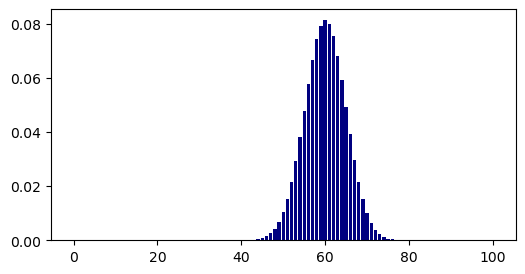

In [9]:
xs = np.arange(101)

plt.figure(figsize=(6, 3))
plt.bar(xs, X.pmf(xs), color='navy');

Suppose, due to budget constraints, you can only poll 10 people instead of 100. Create a new random variable $Y$ fitting this scenario and create the same chart you made above.

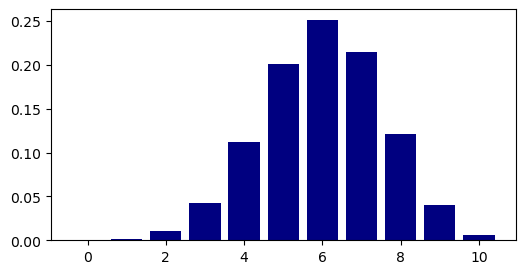

In [10]:
Y = stats.binom(10, 0.6)
ys = np.arange(11)

plt.figure(figsize=(6, 3))
plt.bar(ys, Y.pmf(ys), color='navy');

### Situation 2: Seltzer Addicts
Suppose you work at a startup that offers free snacks and drinks as part of its in-office perks. Unfortunately, some of your coworkers seem to take unfair advantage of this perk.

Matt drinks, on average, 4 seltzers per day. Create a random variable $M$ that represents his daily seltzer intake. What distribution should you use to model this?

In [11]:
M = stats.poisson(4)

This month, you spent 20 days in the office. Simulate 20 days worth of Matt's seltzer consumption.

In [12]:
np.random.seed(123)
matt_seltzers = M.rvs(20)

In [13]:
matt_seltzers

array([4, 6, 2, 3, 7, 3, 4, 5, 4, 6, 5, 5, 4, 3, 3, 7, 1, 7, 3, 2])

How many days did he have 6 or more seltzers?

In [14]:
sum(matt_seltzers >= 6)

5

Compare that with the theoretical probability of Matt having 6 or more seltzers on a given day.

In [15]:
1 - M.cdf(5)

0.21486961296959484

Your other coworker, Xiaofei, drinks an average of 5 seltzers per day. Create another random variable $X$ that corresponds to his seltzer consumption.

In [16]:
X = stats.poisson(5)

Simulate 100 days of seltzer consumption for both Matt and Xiaofei. Answer the following:

* How often does Matt drink _more_ seltzers than Xiaofei?
* Your office manager only buys one 12 pack of seltzer per day. How often is there not enough seltzer for both Matt and Xiaofei to consume?
* Suppose you like seltzer too. On average, how many of the 12 seltzers are left over for you? (**This one is a little tougher than it seems!**)

In [17]:
np.random.seed(123)
m100 = M.rvs(100)
x100 = X.rvs(100)

In [18]:
np.mean(m100 > x100)

0.28

In [19]:
np.mean(m100 + x100 > 12)

0.09

In [20]:
np.mean(
    12 - np.where(m100 + x100 > 12, 12, m100 + x100)
)

3.5

## Conclusions
- Random variables are "processes" for generating random values according to some distribution
- Random variables don't take on values until you "realize" them by performing some experiment
- Distributions describe where the probability of a random variable lies and there are many tools for calculating and thinking about these probabilities